Đang đọc file thuộc tính...
Tổng số lượng mẫu ảnh: 202599
Các cột dữ liệu: ['image_id', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes'] ...

--- THỐNG KÊ SỐ LƯỢNG MẪU (Có thuộc tính) ---
No_Beard             169158
Male                  84434
Wavy_Hair             64744
Black_Hair            48472
Straight_Hair         42222
Brown_Hair            41572
Wearing_Earrings      38276
Bangs                 30709
Blond_Hair            29983
Wearing_Necklace      24913
Receding_Hairline     16163
Wearing_Necktie       14732
Eyeglasses            13193
Sideburns             11449
Wearing_Hat            9818
Gray_Hair              8499
Mustache               8417
Bald                   4547
dtype: int64


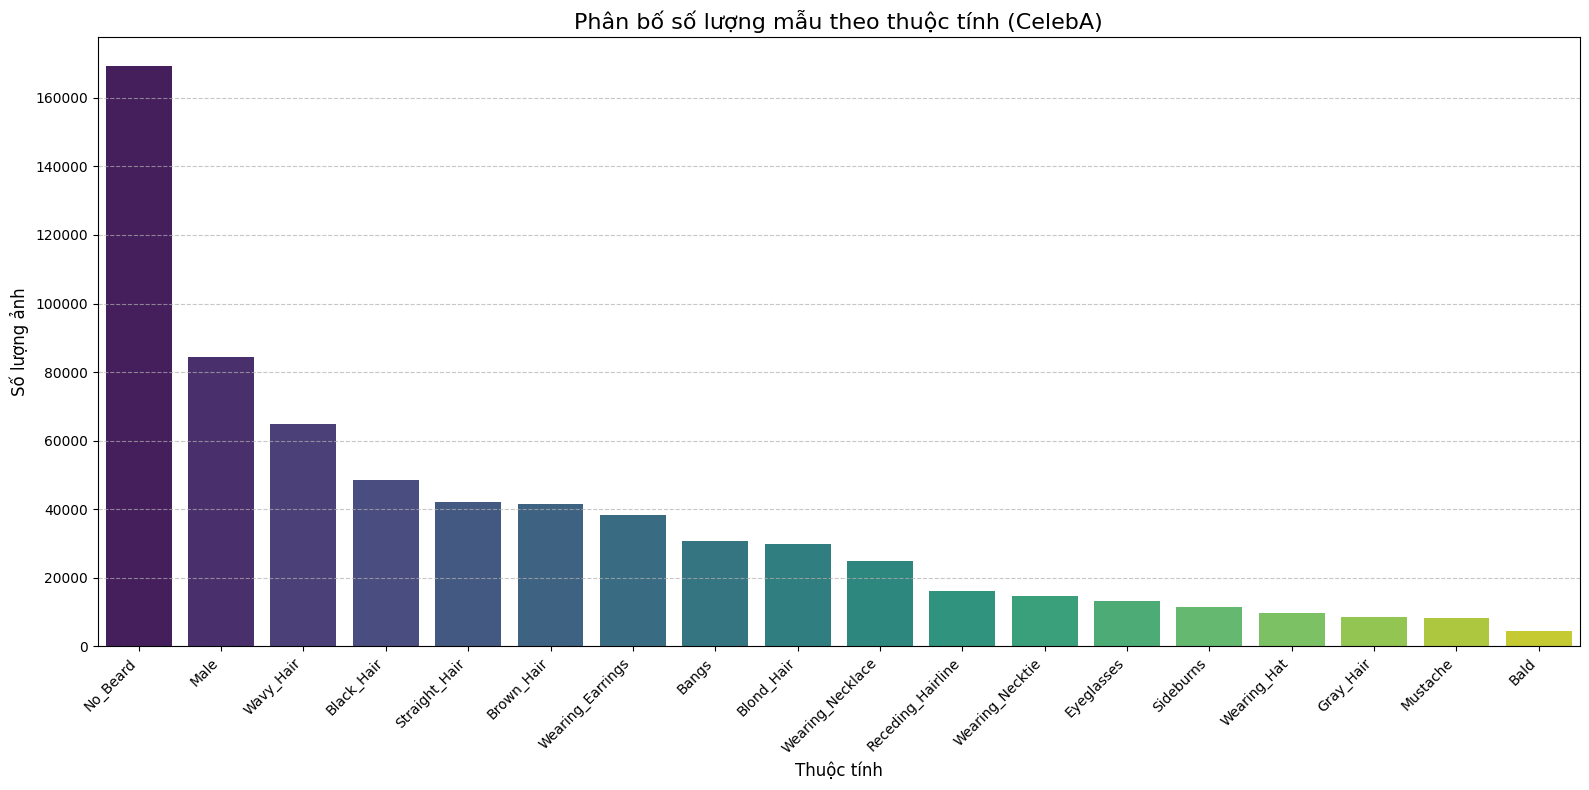


--- HIỂN THỊ ẢNH MẪU ---


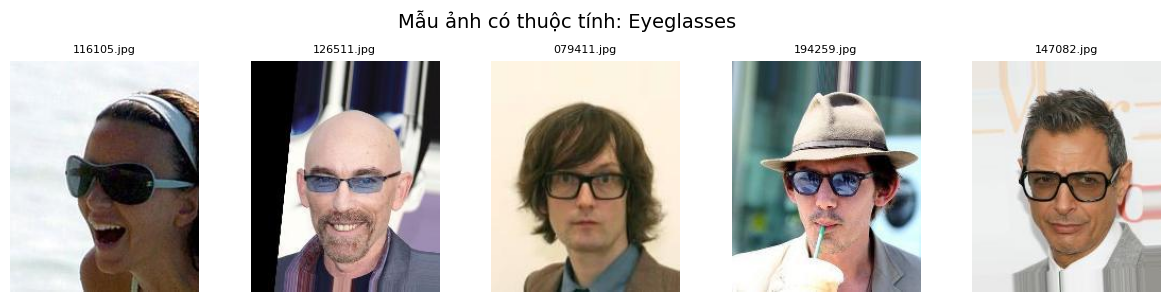

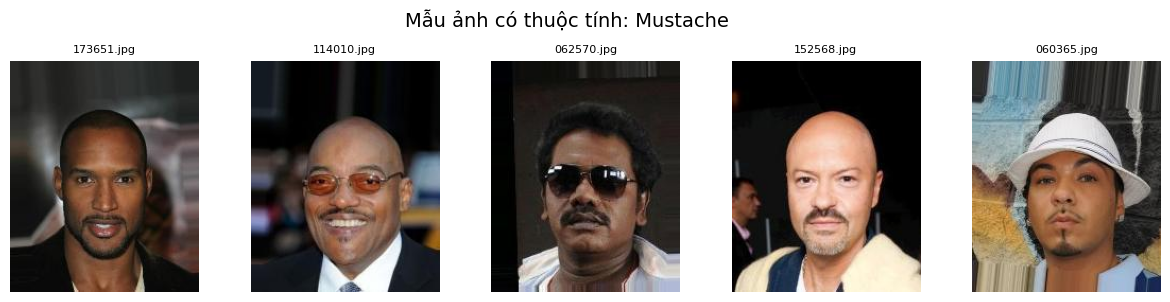

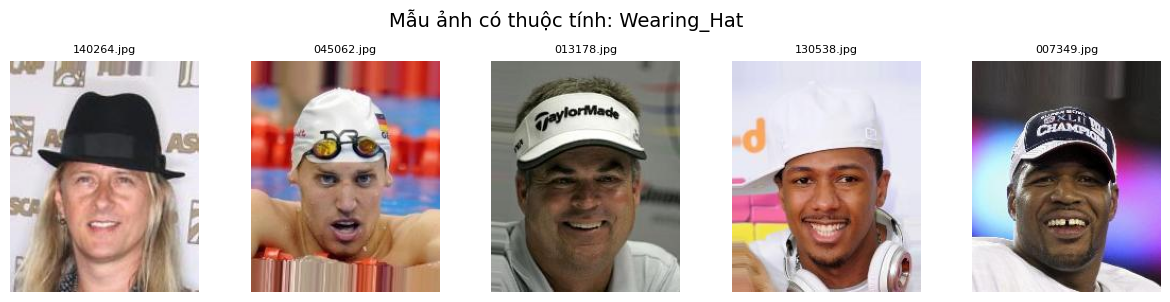

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import numpy as np

# Cấu hình hiển thị
plt.rcParams['figure.figsize'] = (15, 8)
pd.set_option('display.max_columns', None)

# 1. ĐỊNH NGHĨA ĐƯỜNG DẪN VÀ FEATURES
# Trên Kaggle, dataset CelebA thường nằm ở đường dẫn này
ATTR_PATH = '/kaggle/input/celeba-dataset/list_attr_celeba.csv'
IMG_DIR = '/kaggle/input/celeba-dataset/img_align_celeba/img_align_celeba'

# Danh sách thuộc tính bạn yêu cầu
target_features = [
    'Male', 'Bald', 'Bangs', 'Black_Hair', 'Blond_Hair', 'Brown_Hair', 'Gray_Hair',
    'Straight_Hair', 'Wavy_Hair', 'Receding_Hairline', 'Mustache', 'Sideburns', 
    'No_Beard', 'Eyeglasses', 'Wearing_Hat', 'Wearing_Earrings', 'Wearing_Necklace', 
    'Wearing_Necktie'
]

# 2. ĐỌC DỮ LIỆU THUỘC TÍNH
if not os.path.exists(ATTR_PATH):
    print(f"Lỗi: Không tìm thấy file tại {ATTR_PATH}")
    print("Vui lòng kiểm tra lại đường dẫn dataset trên Kaggle.")
else:
    print("Đang đọc file thuộc tính...")
    df = pd.read_csv(ATTR_PATH)
    
    # Dataset gốc dùng -1 cho False và 1 cho True. Ta chuyển về 0 và 1 cho dễ tính toán
    df.replace(-1, 0, inplace=True)
    
    print(f"Tổng số lượng mẫu ảnh: {len(df)}")
    print(f"Các cột dữ liệu: {df.columns.tolist()[:5]} ...")

    # 3. THỐNG KÊ SỐ LƯỢNG VÀ VẼ PHÂN BỔ
    # Tính tổng số lượng mẫu có giá trị = 1 cho từng thuộc tính
    feature_counts = df[target_features].sum().sort_values(ascending=False)
    
    print("\n--- THỐNG KÊ SỐ LƯỢNG MẪU (Có thuộc tính) ---")
    print(feature_counts)

    # Vẽ biểu đồ cột
    plt.figure(figsize=(16, 8))
    sns.barplot(x=feature_counts.index, y=feature_counts.values, palette='viridis')
    plt.title('Phân bố số lượng mẫu theo thuộc tính (CelebA)', fontsize=16)
    plt.xlabel('Thuộc tính', fontsize=12)
    plt.ylabel('Số lượng ảnh', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # 4. HIỂN THỊ ẢNH MẪU THEO THUỘC TÍNH
    def show_samples(feature_name, num_samples=5):
        """Hiển thị 5 ảnh ngẫu nhiên có thuộc tính feature_name"""
        # Lấy các dòng có feature_name == 1
        sample_df = df[df[feature_name] == 1].sample(n=num_samples, random_state=42)
        
        plt.figure(figsize=(15, 3))
        plt.suptitle(f"Mẫu ảnh có thuộc tính: {feature_name}", fontsize=14, y=1.05)
        
        for idx, (_, row) in enumerate(sample_df.iterrows()):
            img_name = row['image_id']
            img_path = os.path.join(IMG_DIR, img_name)
            
            if os.path.exists(img_path):
                img = cv2.imread(img_path)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                plt.subplot(1, num_samples, idx + 1)
                plt.imshow(img)
                plt.axis('off')
                plt.title(img_name, fontsize=8)
            else:
                print(f"Không tìm thấy ảnh: {img_path}")
        
        plt.show()

    # Chọn ra vài thuộc tính tiêu biểu để hiển thị ảnh
    print("\n--- HIỂN THỊ ẢNH MẪU ---")
    # Ví dụ: Hiển thị 3 thuộc tính khác nhau
    selected_features_to_show = ['Eyeglasses', 'Mustache', 'Wearing_Hat']
    
    for feat in selected_features_to_show:
        if feat in df.columns:
            show_samples(feat)